# 04 · Phân loại bằng Logistic Regression

So sánh ba tỷ lệ chia trên tập development, hai biểu diễn đầu vào và hai chế độ trọng số lớp. Nhánh PCA giữ `floor(d/3)` thành phần, với `d` là số đặc trưng sau mã hóa trên train. Dùng cùng tập chia ở mỗi phép so sánh.

Mỗi cấu hình dùng solver liblinear và chọn `C` trong 0,01, 0,1, 1 và 10 cùng regularization L1 hoặc L2. Dùng Average Precision trung bình qua 5 fold train có phân tầng và giữ nhóm khách hàng trùng. Pipeline tiền xử lý và PCA được fit lại trong từng fold. Sau khi chọn tham số, fit lại trên toàn bộ train và đánh giá validation. Giữ ngưỡng dự đoán lớp 1 ở 0,5.

PR-AUC trong bảng là diện tích hình thang dưới đường Precision–Recall. Cột `cv_average_precision` ghi độ đo dùng để chọn tham số. Các độ đo train được tính trên dữ liệu đã dùng để fit lại, giúp đọc chênh lệch train và validation.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import display
from sklearn.metrics import precision_recall_curve, roc_curve

root = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "src" / "classification.py").is_file()
)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src import config
from src.classification import evaluate_logistic

sns.set_theme(style="whitegrid")
figures = config.FIGURES_CLASSIFICATION_DIR
figures.mkdir(parents=True, exist_ok=True)
config.TABLES_DIR.mkdir(parents=True, exist_ok=True)
metrics, predictions = evaluate_logistic()
metrics.to_csv(config.TABLES_DIR / "logistic_classification_metrics.csv", index=False)

In [2]:
validation = metrics.loc[metrics["partition"].eq("validation")].copy()
train = metrics.loc[metrics["partition"].eq("train")]
scenario = ["split", "representation", "class_weight"]
validation = validation.merge(
    train[scenario + ["pr_auc"]].rename(columns={"pr_auc": "train_pr_auc"}),
    on=scenario, validate="one_to_one",
)
validation["pr_auc_gap"] = validation["train_pr_auc"] - validation["pr_auc"]
display(validation[scenario + [
    "n_features", "C", "penalty", "cv_average_precision", "accuracy", "precision",
    "recall", "f1", "pr_auc", "roc_auc", "pr_auc_gap", "fp", "fn"
]].round(3))

,split,representation,class_weight,n_features,C,penalty,cv_average_precision,accuracy,precision,recall,f1,pr_auc,roc_auc,pr_auc_gap,fp,fn
0,80_20,full,default,37,0.1,l1,0.670,0.880,0.762,0.296,0.427,0.631,0.875,0.065,5,38
1,80_20,full,balanced,37,0.1,l1,0.656,0.821,0.444,0.741,0.556,0.627,0.873,0.056,50,14
2,80_20,pca_one_third,default,12,1.0,l1,0.627,0.888,0.750,0.389,0.512,0.582,0.854,0.069,7,33
3,80_20,pca_one_third,balanced,12,1.0,l2,0.628,0.821,0.446,0.759,0.562,0.601,0.864,0.029,51,13
4,70_30,full,default,37,1.0,l1,0.647,0.894,0.740,0.457,0.565,0.651,0.890,0.061,13,44
5,70_30,full,balanced,37,0.1,l1,0.650,0.822,0.446,0.765,0.564,0.669,0.895,0.005,77,19
6,70_30,pca_one_third,default,12,10.0,l1,0.620,0.885,0.694,0.420,0.523,0.624,0.878,0.012,15,47
7,70_30,pca_one_third,balanced,12,10.0,l1,0.614,0.816,0.441,0.827,0.575,0.640,0.885,-0.026,85,14
8,60_40,full,default,37,0.1,l2,0.676,0.880,0.657,0.411,0.506,0.627,0.880,0.106,23,63
9,60_40,full,balanced,37,1.0,l1,0.668,0.821,0.442,0.748,0.556,0.590,0.878,0.108,101,27


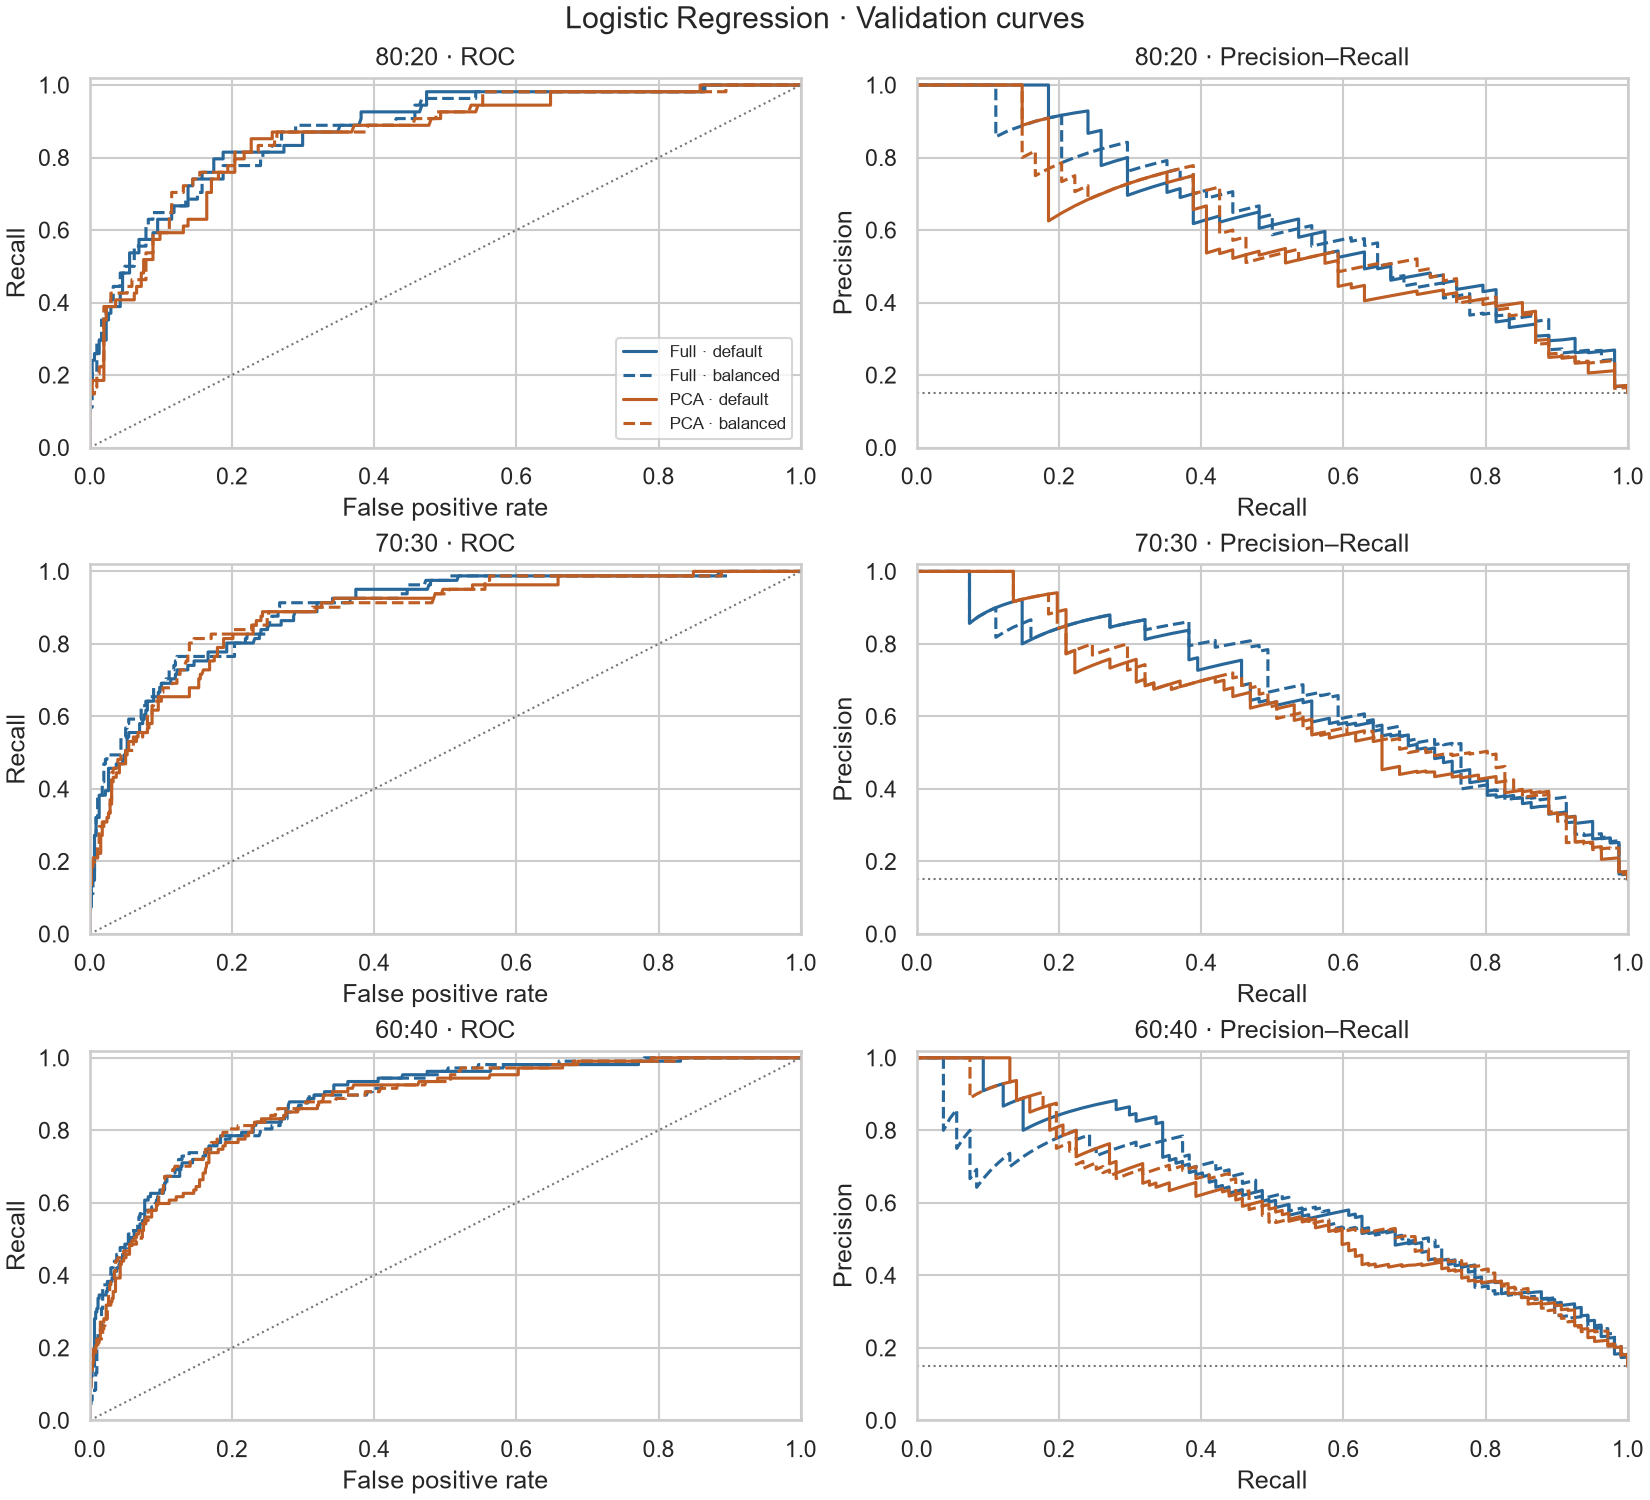

In [3]:
splits = ["80_20", "70_30", "60_40"]
representations = {"full": "Full", "pca_one_third": "PCA"}
colors = {"full": "#28679A", "pca_one_third": "#BF5E24"}
styles = {"default": "-", "balanced": "--"}
fig, axes = plt.subplots(3, 2, figsize=(11, 10), layout="constrained")
for index, split in enumerate(splits):
    roc_ax, pr_ax = axes[index]
    split_predictions = predictions.loc[predictions["split"].eq(split)]
    for (representation, weight), scores in split_predictions.groupby(
        ["representation", "class_weight"], sort=False
    ):
        labels, probabilities = scores["Response"], scores["probability_response_1"]
        fpr, tpr, _ = roc_curve(labels, probabilities)
        precision, recall, _ = precision_recall_curve(labels, probabilities)
        style = {
            "color": colors[representation], "linestyle": styles[weight],
            "label": f"{representations[representation]} · {weight}",
        }
        roc_ax.plot(fpr, tpr, **style)
        pr_ax.plot(recall, precision, **style)

    prevalence = split_predictions["Response"].mean()
    roc_ax.plot([0, 1], [0, 1], color="#767676", linestyle=":", linewidth=1)
    pr_ax.axhline(prevalence, color="#767676", linestyle=":", linewidth=1)
    ratio = split.replace("_", ":")
    roc_ax.set(title=f"{ratio} · ROC", xlabel="False positive rate", ylabel="Recall")
    pr_ax.set(title=f"{ratio} · Precision–Recall", xlabel="Recall", ylabel="Precision")
    for ax in (roc_ax, pr_ax):
        ax.set(xlim=(0, 1), ylim=(0, 1.02))
axes[0, 0].legend(loc="lower right", fontsize=8)
fig.suptitle("Logistic Regression · Validation curves")
fig.savefig(figures / "logistic_roc_pr_curves.png", dpi=config.FIGURE_DPI)
plt.show()
plt.close(fig)

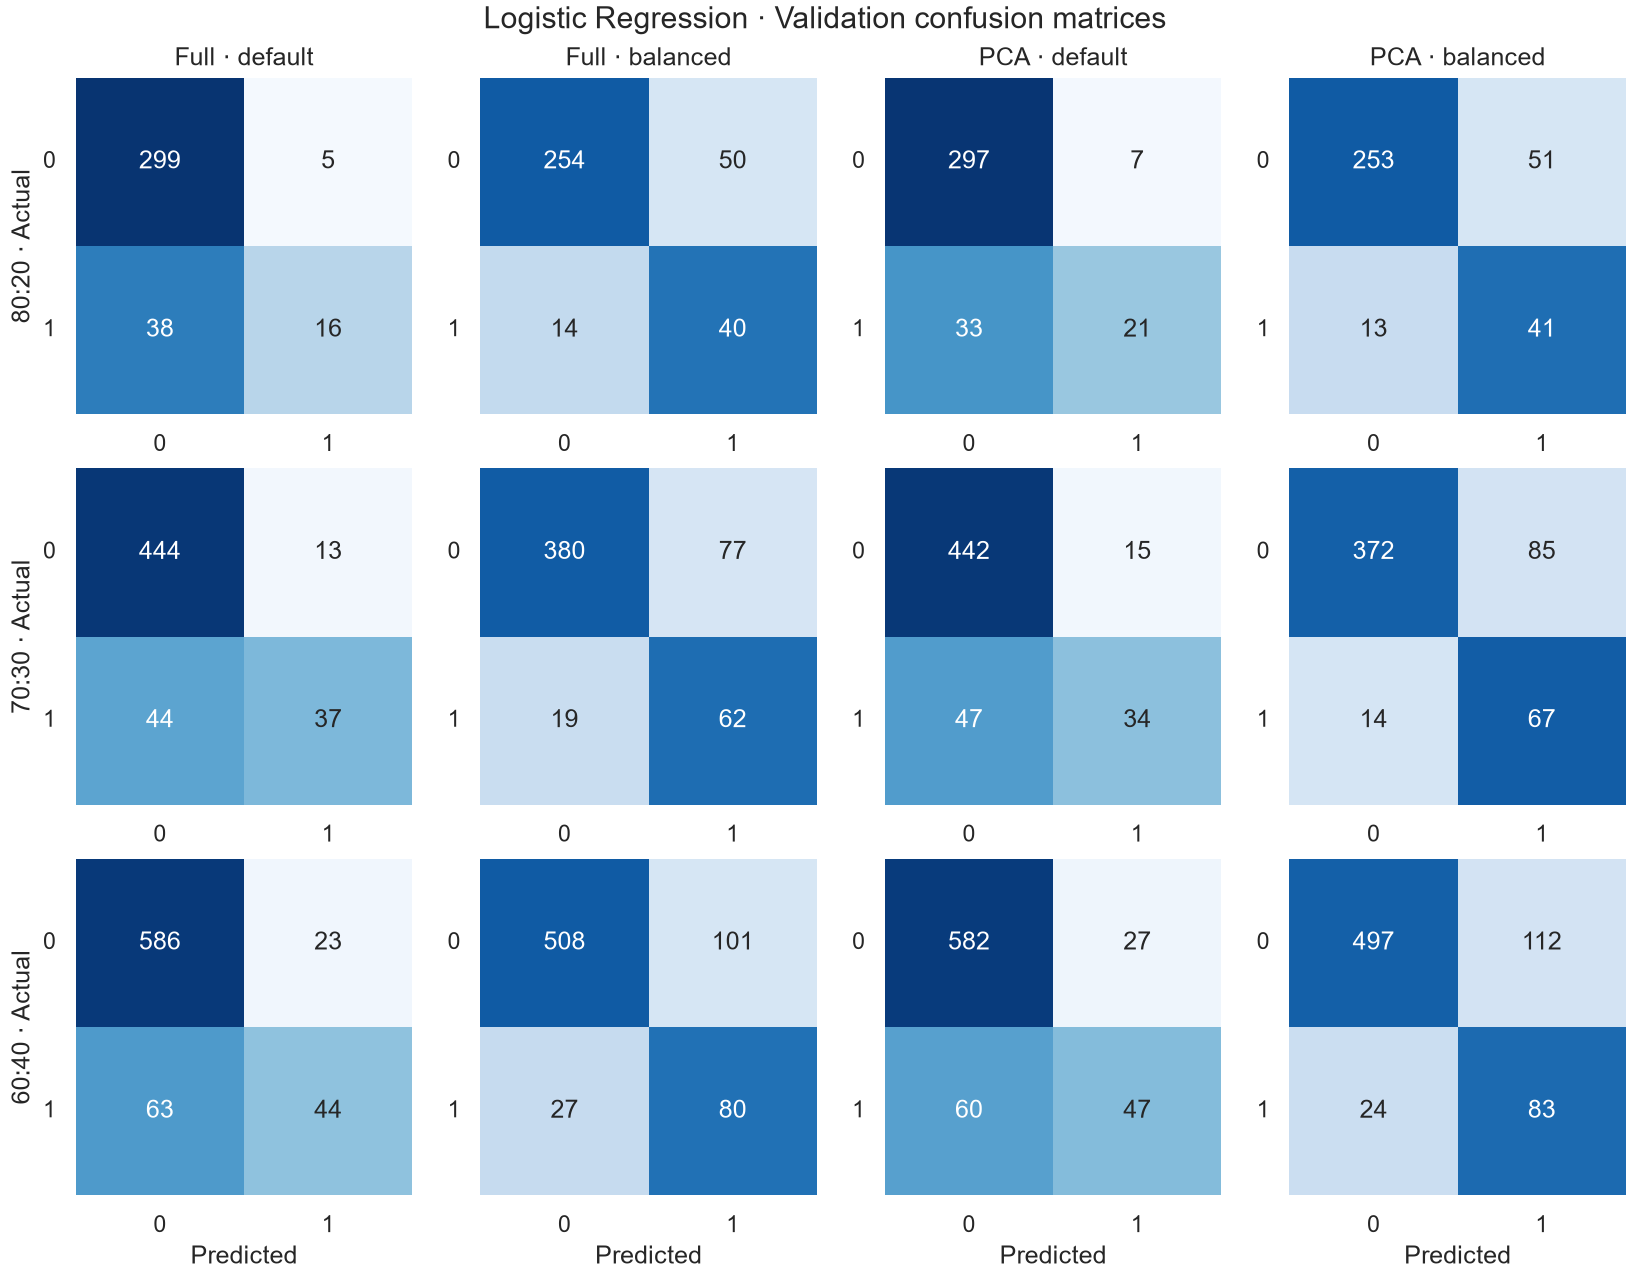

In [4]:
settings = [(representation, weight) for representation in representations for weight in styles]
indexed = validation.set_index(scenario)
fig, axes = plt.subplots(3, 4, figsize=(11, 8.5), layout="constrained")
for row_index, split in enumerate(splits):
    for col_index, (representation, weight) in enumerate(settings):
        result = indexed.loc[(split, representation, weight)]
        counts = result[["tn", "fp", "fn", "tp"]].to_numpy(dtype=int).reshape(2, 2)
        rates = counts / counts.sum(axis=1, keepdims=True)
        ax = axes[row_index, col_index]
        sns.heatmap(
            rates, annot=counts, fmt="d", cmap="Blues", vmin=0, vmax=1,
            cbar=False, square=True, ax=ax,
        )
        if row_index == 0:
            ax.set_title(f"{representations[representation]} · {weight}")
        if col_index == 0:
            ratio = split.replace("_", ":")
            ax.set_ylabel(f"{ratio} · Actual")
        if row_index == len(splits) - 1:
            ax.set_xlabel("Predicted")
        ax.tick_params(axis="y", labelrotation=0)
fig.suptitle("Logistic Regression · Validation confusion matrices")
fig.savefig(figures / "logistic_confusion_matrices.png", dpi=config.FIGURE_DPI)
plt.show()
plt.close(fig)

## Nhận xét trên validation

**Cân bằng lớp.** Ở ngưỡng 0,5, cân bằng lớp tăng recall và giảm precision trong cả sáu cặp cấu hình. Với bộ đặc trưng đầy đủ ở tỷ lệ 80:20, số khách hàng hưởng ứng bị bỏ sót giảm từ 38 xuống 14. Số dự đoán hưởng ứng sai tăng từ 5 lên 50.

**Giảm chiều.** Bộ đặc trưng đầy đủ đạt PR-AUC cao hơn PCA trong 5/6 cặp cùng tỷ lệ chia và chế độ trọng số. Ở cặp 60:40 cân bằng lớp, PCA đạt PR-AUC 0,601 và bộ đầy đủ đạt 0,590. Mức giảm từ 37 xuống 12 chiều có thể hữu ích khi cần biểu diễn gọn hơn.

**Chênh lệch train và validation.** Ở tỷ lệ 60:40, nhánh đặc trưng đầy đủ có PR-AUC train cao hơn validation khoảng 0,11 ở cả hai chế độ trọng số. Mức chênh này cho thấy kết quả trên train có thể đánh giá quá cao khả năng khái quát. Logistic là mốc so sánh hữu ích trên các tập validation. Lựa chọn trọng số phụ thuộc vào chi phí bỏ sót khách hàng hưởng ứng và chi phí liên hệ nhầm.